# Anticipez les besoins en consommation de bâtiments — Ville de Seattle

**Objectif** : prédire la consommation totale d'énergie (`SiteEnergyUse(kBtu)`) des bâtiments **non destinés à l'habitation**
à partir de leurs **données structurelles** (taille, usage, date de construction, localisation…), pour éviter des relevés coûteux.

Données : relevés 2016 du *Building Energy Benchmarking* de Seattle ([source](https://data.seattle.gov/Built-Environment/Building-Energy-Benchmarking-Data-2015-Present/teqw-tu6e/about_data)).
Chaque année, les propriétaires de grands bâtiments déclarent à la ville leur consommation d'énergie ; la ville classe ensuite chaque bâtiment
(type, usage) et contrôle la qualité de la déclaration.

#### Petit lexique

| Terme | Signification |
|---|---|
| **kBtu** | Kilo *British thermal unit*, unité d'énergie américaine (1 kBtu ≈ 0,29 kWh) |
| **pied² (sf)** | Unité de surface américaine (1 pied² ≈ 0,093 m², donc 10 000 pieds² ≈ 930 m²) |
| **GFA** | *Gross Floor Area* : surface de plancher du bâtiment, en pieds² |
| **EUI** | *Energy Use Intensity* : consommation divisée par la surface (kBtu par pied²). Permet de comparer des bâtiments de tailles différentes |
| **Médiane** | Valeur du milieu : la moitié des bâtiments est au-dessus, l'autre moitié en dessous. Contrairement à la moyenne, elle n'est pas tirée vers le haut par quelques valeurs géantes |
| **Quartiles (25 %, 75 %)** | Un quart des bâtiments est en dessous du 1er quartile, trois quarts en dessous du 3e |
| **Échelle log** | Échelle où chaque graduation est 10 fois plus grande que la précédente (1, 10, 100…). Indispensable quand les valeurs vont de quelques milliers à des centaines de millions |
| **Corrélation** | Mesure entre -1 et 1 du lien entre deux variables : proche de 1 = elles augmentent ensemble, proche de 0 = pas de lien |
| **Fuite de données** | Utiliser pour prédire une information qui ne sera pas connue au moment de la prédiction. Le modèle paraît excellent mais est inutilisable en pratique |
| **Feature / cible** | Les *features* sont les informations données au modèle ; la *cible* est ce qu'il doit prédire |

# Analyse Exploratoire

### Import des modules

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

### 1. Découverte des données

In [33]:
building_consumption = pd.read_csv("../data/2016_Building_Energy_Benchmarking.csv")
building_consumption.shape

(3376, 46)

`(3376, 46)` = **3 376 lignes** et **46 colonnes**. Chaque ligne est un bâtiment, chaque colonne une information sur ce bâtiment.

In [34]:
# On regarde comment un batiment est défini dans ce jeu de données
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


Les 5 premières lignes du fichier (ici, 5 hôtels du centre-ville). Chaque bâtiment est identifié par un numéro
unique attribué par la ville (`OSEBuildingID`) et décrit par son nom, son adresse, son quartier, son année de construction, sa surface
et ses consommations. Le tableau est trop large pour l'écran : il continue sur plusieurs blocs.

In [35]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
building_consumption.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

Pour chaque colonne, `Non-Null Count` donne le nombre de bâtiments où la valeur est renseignée
(s'il est inférieur à 3 376, il manque des valeurs) et `Dtype` donne le type (`int64` / `float64` = nombre, `object` = texte, `bool` = vrai/faux).
- `Comments` : **0 valeur**, la colonne est vide.
- `SecondLargestPropertyUseType` (1 679) et `ThirdLargestPropertyUseType` (596) : beaucoup de manquants, mais c'est **normal** —
  la plupart des bâtiments n'ont qu'un ou deux usages.
- `ENERGYSTARScore` (2 533) : un quart de manquants.
- Les colonnes essentielles (type, surface, année, localisation) sont presque complètes.

#### Sens des colonnes

Les 46 colonnes se regroupent en familles. La dernière colonne du tableau indique si chacune pourra servir à prédire.

| Famille | Colonnes | Rôle pour le projet |
|---|---|---|
| Identifiants | `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber` | Identifient un bâtiment, aucun pouvoir prédictif |
| Constantes | `DataYear` (2016), `City` (Seattle), `State` (WA) | Une seule valeur → inutiles |
| Type / usage | `BuildingType`, `PrimaryPropertyType`, `ListOfAllPropertyUseTypes`, `Largest/Second/ThirdLargestPropertyUseType` (+ `GFA`) | **Structurel** : usage du bâtiment et surface par usage |
| Localisation | `ZipCode`, `CouncilDistrictCode`, `Neighborhood`, `Latitude`, `Longitude` | **Structurel** |
| Bâti | `YearBuilt`, `NumberofBuildings`, `NumberofFloors`, `PropertyGFATotal`, `PropertyGFAParking`, `PropertyGFABuilding(s)` | **Structurel** : âge, taille (GFA = *Gross Floor Area*, en pieds²) |
| Score | `ENERGYSTARScore`, `YearsENERGYSTARCertified` | Score 1-100 **calculé à partir des consommations** relevées |
| Intensités | `SiteEUI`, `SourceEUI` (+ `WN` = corrigé météo) | Consommation / surface → **dérivées de la cible** |
| Consommations | `SiteEnergyUse(kBtu)` (**cible**), `SiteEnergyUseWN`, `SteamUse`, `Electricity`, `NaturalGas` | Issues du **relevé** |
| Émissions | `TotalGHGEmissions`, `GHGEmissionsIntensity` | Calculées à partir des consommations |
| Qualité | `DefaultData`, `ComplianceStatus`, `Outlier`, `Comments` | Qualité du relevé |

⚠️ **Fuite de données** : toutes les colonnes issues du relevé (intensités, consommations par source, émissions, score ENERGY STAR)
ne seront **pas disponibles** pour un bâtiment non encore mesuré. Elles servent à l'analyse mais seront **exclues du modèle**.

### 2. Choix de la variable cible

Plusieurs colonnes pourraient servir de cible. Il faut en choisir **une seule** pour tout le projet.

| Candidate | Signification | Verdict |
|---|---|---|
| `SiteEnergyUse(kBtu)` | Énergie totale consommée sur site en 2016 | ✅ **Retenue** : c'est exactement la « consommation totale d'énergie » demandée |
| `SiteEnergyUseWN(kBtu)` | Même chose, corrigée des conditions météo (*Weather Normalized*) | ❌ Valeur recalculée par modèle, pas la consommation réelle mesurée |
| `SiteEUI(kBtu/sf)` / `SiteEUIWN` | Consommation divisée par la surface | ❌ Intensité, pas consommation totale (c'est la cible divisée par la surface) |
| `SourceEUI(kBtu/sf)` / `SourceEUIWN` | Énergie primaire (pertes de production et de transport incluses) par surface | ❌ Dépend des coefficients de conversion de chaque source, pas seulement du bâtiment |
| `TotalGHGEmissions` / `GHGEmissionsIntensity` | Émissions de CO2 | ❌ Autre objectif (émissions), calculé à partir des consommations par source |

Une fois la cible choisie, **toutes les autres candidates deviennent des fuites de données** : elles sont calculées à partir du même relevé
et ne seront pas connues pour un bâtiment non mesuré.

In [36]:
cible = "SiteEnergyUse(kBtu)"
candidates = [cible, "SiteEnergyUseWN(kBtu)", "SiteEUI(kBtu/sf)", "SourceEUI(kBtu/sf)", "TotalGHGEmissions"]
building_consumption[candidates].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
SiteEnergyUse(kBtu),3371.0,5403667.3,21610628.6,0.0,925128.6,1803753.2,4222455.2,873923712.0
SiteEnergyUseWN(kBtu),3370.0,5276725.7,15938786.5,0.0,970182.2,1904452.0,4381429.1,471613856.0
SiteEUI(kBtu/sf),3369.0,54.7,56.3,0.0,27.9,38.6,60.4,834.4
SourceEUI(kBtu/sf),3367.0,134.2,139.3,0.0,74.7,96.2,143.9,2620.0
TotalGHGEmissions,3367.0,119.7,538.8,-0.8,9.5,33.9,93.9,16871.0


Une ligne par candidate, avec le nombre de valeurs (`count`), la moyenne (`mean`), l'écart-type (`std`, la dispersion),
le minimum, les quartiles (25 %, 50 % = médiane, 75 %) et le maximum.
- Pour la cible `SiteEnergyUse` : **moyenne 5,4 millions de kBtu mais médiane 1,8 million**, et un maximum de 874 millions.
  Une moyenne 3 fois plus grande que la médiane signifie que **quelques bâtiments géants tirent la moyenne vers le haut** : la distribution est très déséquilibrée.
- `min = 0` : certains bâtiments déclarent une consommation nulle, ce qui est impossible → erreurs à retirer.
- `TotalGHGEmissions` a un minimum **négatif** (-0,8) : autre incohérence de saisie.

### 3. Nettoyage des données

#### Journal des filtrages

Chaque suppression de bâtiments passe par la fonction `filtrer`, qui affiche et enregistre le nombre de lignes **avant** et **après**.
On sait ainsi exactement combien de bâtiments chaque règle retire ; le récapitulatif complet est affiché à la fin du nettoyage.

In [37]:
journal = []

def filtrer(df, masque, etape):
    """Garde les lignes où `masque` est vrai et enregistre l'étape dans le journal."""
    avant = len(df)
    df = df[masque]
    journal.append({"Étape": etape, "Avant": avant, "Après": len(df), "Retirées": avant - len(df)})
    print(f"{etape} : {avant} → {len(df)} ({avant - len(df)} retirées)")
    return df

#### Filtrage des bâtiments non destinés à l'habitation

In [38]:
building_consumption["BuildingType"].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

Nombre de bâtiments par catégorie administrative (`BuildingType`), attribuée par la ville.

| Code | Signification | Gardé ? |
|---|---|---|
| `NonResidential` | Bâtiment tertiaire privé (bureaux, hôtels, commerces…) | ✅ |
| `Multifamily LR (1-4)` / `MR (5-9)` / `HR (10+)` | Immeubles d'habitation (*Low / Mid / High Rise*, nombre d'étages entre parenthèses) | ❌ logements |
| `SPS-District K-12` | Écoles publiques (*Seattle Public Schools*, de la maternelle au lycée : *Kindergarten to 12th grade*) | ✅ |
| `Nonresidential COS` | Bâtiments de la ville (*City Of Seattle*) : bibliothèques, commissariats… | ✅ |
| `Nonresidential WA` | Bâtiment de l'État de Washington | ✅ |
| `Campus` | Ensemble de bâtiments gérés ensemble (universités, sites industriels) | ✅ |

Les logements représentent **plus de la moitié** du fichier (1 708 bâtiments) : on les retire, le projet porte sur le non résidentiel.

In [39]:
df = building_consumption.copy()
df = filtrer(df, ~df["BuildingType"].str.startswith("Multifamily"), "BuildingType non résidentiel")
df["PrimaryPropertyType"].value_counts()

BuildingType non résidentiel : 3376 → 1668 (1708 retirées)


PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Restaurant                      12
Refrigerated Warehouse          12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64

1 708 logements retirés, il reste **1 668 bâtiments**. Le tableau donne ensuite leur usage principal
(`PrimaryPropertyType`) : surtout des bureaux (*Small- and Mid-Sized Office* et *Large Office*), des usages divers (*Other*) et des entrepôts (*Warehouse*).

Quelques bâtiments classés non résidentiels ont pourtant `Low-Rise Multifamily` comme usage principal : ce sont des logements, on les retire aussi.
Les `Residence Hall` (résidences universitaires) et `Senior Care Community` sont conservés : ce sont des établissements gérés comme des bâtiments tertiaires.

In [40]:
df = filtrer(df, df["PrimaryPropertyType"] != "Low-Rise Multifamily", "Usage principal non résidentiel")

Usage principal non résidentiel : 1668 → 1665 (3 retirées)


Les 3 logements mal classés sont retirés, il reste **1 665 bâtiments**.

#### Qualité des relevés

In [41]:
print(df["ComplianceStatus"].value_counts(), "\n")
print(df["Outlier"].value_counts())

ComplianceStatus
Compliant                       1546
Error - Correct Default Data      88
Non-Compliant                     17
Missing Data                      14
Name: count, dtype: int64 

Outlier
Low outlier     14
High outlier     2
Name: count, dtype: int64


La ville contrôle chaque déclaration et lui attribue un statut (`ComplianceStatus`) :
- `Compliant` (1 546) : déclaration **conforme** ;
- `Error - Correct Default Data` (88) : déclaration complétée avec des **valeurs par défaut** au lieu de vraies mesures ;
- `Non-Compliant` (17) : déclaration jugée **non conforme** ;
- `Missing Data` (14) : **données manquantes**.

La colonne `Outlier` signale 16 relevés jugés **aberrants** par la ville (14 anormalement bas, 2 anormalement hauts).

In [42]:
df.groupby("ComplianceStatus")[cible].describe()

,count,mean,std,min,25%,50%,75%,max
ComplianceStatus,,,,,,,,
Compliant,1546.0,8.867785e+06,3.132518e+07,57133.19922,1.248602e+06,2.732167e+06,7301811.625,873923712.0
Error - Correct Default Data,88.0,2.960782e+06,2.571226e+06,0.00000,1.534597e+06,2.102175e+06,3060542.500,13567774.0
Missing Data,14.0,0.000000e+00,0.000000e+00,0.00000,0.000000e+00,0.000000e+00,0.000,0.0
Non-Compliant,15.0,5.437945e+06,1.234232e+07,0.00000,5.833195e+04,1.613634e+05,411353.750,41399504.0


La consommation selon le statut de la déclaration.
- `Missing Data` : consommation moyenne de **0** → aucun relevé exploitable.
- `Non-Compliant` : médiane de 161 000 kBtu, soit **17 fois moins** que les relevés conformes (2,7 millions) → valeurs anormales.

**Décision** : on ne garde que les relevés **conformes**, non signalés comme aberrants, avec une consommation **strictement positive** :
apprendre sur des relevés faux dégraderait le modèle.

In [43]:
df = filtrer(df, df["ComplianceStatus"] == "Compliant", "Relevé conforme")
df = filtrer(df, df["Outlier"].isna(), "Non signalé outlier par la ville")
df = filtrer(df, df[cible] > 0, "Consommation > 0")

Relevé conforme : 1665 → 1546 (119 retirées)
Non signalé outlier par la ville : 1546 → 1546 (0 retirées)
Consommation > 0 : 1546 → 1546 (0 retirées)


Le filtre « relevé conforme » retire 119 bâtiments (il en reste **1 546**). Les deux filtres suivants ne retirent
**rien** : les relevés aberrants et les consommations nulles faisaient déjà partie des relevés non conformes. On les garde comme **garde-fous**
(sur de nouvelles données, ils joueraient leur rôle).

⚠️ Ce filtre retire **la quasi-totalité des écoles publiques** (`SPS-District K-12`) : 90 sur 98 n'ont pas de relevé conforme
(valeurs par défaut ou données manquantes). Les écoles restent représentées par les établissements classés `NonResidential` et `Campus`,
mais le modèle sera moins fiable sur ce type de bâtiment.

#### Suppression des colonnes inutiles

In [44]:
colonnes_inutiles = [
    "DataYear", "City", "State",                     # constantes
    "PropertyName", "Address", "TaxParcelIdentificationNumber",  # identifiants texte
    "Comments",                                      # 100 % vide
    "YearsENERGYSTARCertified",                      # > 90 % vide
    "ComplianceStatus", "Outlier", "DefaultData",    # qualité, déjà utilisées pour filtrer
]
df = df.drop(columns=colonnes_inutiles).set_index("OSEBuildingID")
df.shape

(1546, 34)

On passe de 46 à **34 colonnes**. Les colonnes retirées ne peuvent pas aider à prédire : valeurs identiques
pour tous (année, ville, État), textes d'identification (nom, adresse), colonnes vides, ou indicateurs de qualité déjà utilisés pour filtrer.

#### Valeurs manquantes

In [45]:
manquants = df.isna().sum()
(manquants[manquants > 0] / len(df) * 100).round(1).sort_values(ascending=False).to_frame("% manquant")

,% manquant
ThirdLargestPropertyUseTypeGFA,77.6
ThirdLargestPropertyUseType,77.6
SecondLargestPropertyUseTypeGFA,45.6
SecondLargestPropertyUseType,45.6
ENERGYSTARScore,35.6
ZipCode,0.8
LargestPropertyUseType,0.3
LargestPropertyUseTypeGFA,0.3
SiteEUIWN(kBtu/sf),0.1
SiteEnergyUseWN(kBtu),0.1


Pourcentage de bâtiments sans valeur, pour chaque colonne incomplète.

On ne supprime **pas** toutes les lignes ayant une valeur manquante : il ne resterait presque plus de bâtiments.
- `Second/ThirdLargestPropertyUseType` : manquants **par construction** (le bâtiment n'a qu'un ou deux usages) → on les remplacera par « aucun » / 0 m².
- `ENERGYSTARScore` : environ un tiers manquant, et **calculé à partir des consommations** → exclu du modèle.
- Les rares manquants restants (`ZipCode`, `LargestPropertyUseType`…, moins de 1 %) seront traités en préparation des features.

#### Cohérence des données

In [46]:
# Quartiers : la casse n'est pas homogène (« North » / « NORTH »)
df["Neighborhood"] = df["Neighborhood"].str.upper().replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")
df["Neighborhood"].value_counts()

Neighborhood
DOWNTOWN                 350
GREATER DUWAMISH         328
MAGNOLIA / QUEEN ANNE    144
LAKE UNION               142
NORTHEAST                117
EAST                     116
NORTHWEST                 78
BALLARD                   63
NORTH                     59
CENTRAL                   46
DELRIDGE                  41
SOUTHEAST                 31
SOUTHWEST                 31
Name: count, dtype: int64

Un même quartier était écrit de plusieurs façons (« North » / « NORTH ») et aurait été compté comme deux
quartiers différents. Après mise en majuscules, il reste **13 quartiers**. Les deux plus représentés sont **Downtown** (le centre d'affaires)
et **Greater Duwamish** (la zone industrielle et portuaire).

In [47]:
ratio_usage = df["LargestPropertyUseTypeGFA"] / df["PropertyGFATotal"]
print("NumberofBuildings = 0 :", (df["NumberofBuildings"] == 0).sum())
print("NumberofFloors = 0    :", (df["NumberofFloors"] == 0).sum())
print("Surface usage principal > surface totale :", (ratio_usage > 1).sum(),
      "— dont écart > 10 % :", (ratio_usage > 1.1).sum())
df.sort_values("NumberofFloors", ascending=False)[["PrimaryPropertyType", "Neighborhood", "NumberofFloors", "PropertyGFATotal"]].head(5)

NumberofBuildings = 0 : 52
NumberofFloors = 0    : 16
Surface usage principal > surface totale : 180 — dont écart > 10 % : 77


,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFATotal
OSEBuildingID,,,,
21611,Worship Facility,GREATER DUWAMISH,99,21948
775,Large Office,DOWNTOWN,76,1952220
357,Large Office,DOWNTOWN,63,1354987
422,Large Office,DOWNTOWN,56,1605578
399,Large Office,DOWNTOWN,55,1400000


On cherche des valeurs **impossibles**.
- 52 propriétés déclarent **0 bâtiment** et 16 déclarent **0 étage**.
- 180 bâtiments ont une surface d'usage principal **plus grande que leur surface totale**, dont 77 avec plus de 10 % d'écart.
- Le tableau liste les 5 bâtiments les plus hauts : en tête, un **lieu de culte de 99 étages** pour seulement 21 948 pieds² (≈ 2 000 m²), juste devant
  le vrai record de Seattle (76 étages, un grand bureau de Downtown).

**Décisions** :
- `NumberofBuildings = 0` est impossible pour une propriété relevée : c'est un oubli de saisie, la propriété compte au moins
  un bâtiment → **corrigé à 1** (supprimer ces lignes ferait perdre des bâtiments par ailleurs complets).
- `NumberofFloors = 0` : impossible, et on ne peut pas deviner le vrai nombre d'étages → **supprimés**.
- Le lieu de culte de 99 étages : erreur de saisie évidente → **supprimé**.
- Surfaces : un petit écart peut venir d'arrondis ou de déclarations séparées ; au-delà de **10 %**, les surfaces sont incohérentes → **supprimés**.

In [48]:
df.loc[df["NumberofBuildings"] == 0, "NumberofBuildings"] = 1
df = filtrer(df, df["NumberofFloors"] > 0, "NumberofFloors > 0")
df = filtrer(df, df["NumberofFloors"] < 99, "Nombre d'étages plausible")
ratio_usage = df["LargestPropertyUseTypeGFA"] / df["PropertyGFATotal"]
df = filtrer(df, ~(ratio_usage > 1.1), "Surface usage principal ≤ 110 % surface totale")

NumberofFloors > 0 : 1546 → 1530 (16 retirées)
Nombre d'étages plausible : 1530 → 1529 (1 retirées)
Surface usage principal ≤ 110 % surface totale : 1529 → 1454 (75 retirées)


16 bâtiments sans étage, 1 bâtiment de 99 étages et 75 bâtiments aux surfaces incohérentes sont retirés
(75 et non 77 : deux d'entre eux avaient déjà été retirés par les filtres précédents).

Détail technique : on écrit `~(ratio > 1.1)` plutôt que `ratio <= 1.1` pour **conserver** les bâtiments sans usage principal renseigné
(leur ratio est manquant, et `ratio <= 1.1` les aurait supprimés).

In [49]:
pd.DataFrame(journal)

,Étape,Avant,Après,Retirées
0,BuildingType non résidentiel,3376,1668,1708
1,Usage principal non résidentiel,1668,1665,3
2,Relevé conforme,1665,1546,119
3,Non signalé outlier par la ville,1546,1546,0
4,Consommation > 0,1546,1546,0
5,NumberofFloors > 0,1546,1530,16
6,Nombre d'étages plausible,1530,1529,1
7,Surface usage principal ≤ 110 % surface totale,1529,1454,75


Le **récapitulatif du nettoyage**. Chaque ligne est une règle, avec le nombre de bâtiments avant, après, et retirés.
On passe de **3 376 à 1 454 bâtiments**. La plus grosse perte vient du retrait des logements (1 708), qui sont hors sujet ;
le contrôle qualité en retire 119, et les incohérences 92.

### 4. Exploration des données

#### Statistiques descriptives

In [50]:
colonnes_num = ["YearBuilt", "NumberofBuildings", "NumberofFloors", "PropertyGFATotal",
                "PropertyGFAParking", "PropertyGFABuilding(s)", "ENERGYSTARScore",
                "SiteEUI(kBtu/sf)", cible, "TotalGHGEmissions"]
df[colonnes_num].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
YearBuilt,1454.0,1961.4,32.9,1900.0,1930.0,1965.0,1988.0,2015.0
NumberofBuildings,1454.0,1.1,1.1,1.0,1.0,1.0,1.0,27.0
NumberofFloors,1454.0,4.3,6.4,1.0,1.0,2.5,4.0,76.0
PropertyGFATotal,1454.0,114113.4,197034.4,11285.0,28845.0,48315.0,105090.2,2200000.0
PropertyGFAParking,1454.0,14651.1,44964.6,0.0,0.0,0.0,0.0,512608.0
PropertyGFABuilding(s),1454.0,99462.2,172856.4,3636.0,27934.2,46141.5,93981.5,2200000.0
ENERGYSTARScore,936.0,63.5,28.9,1.0,44.0,70.0,88.0,100.0
SiteEUI(kBtu/sf),1454.0,75.7,76.3,1.4,35.0,54.3,85.5,834.4
SiteEnergyUse(kBtu),1454.0,7655969.0,17533614.5,57133.2,1229290.8,2695254.8,7263573.1,291614432.0
TotalGHGEmissions,1454.0,161.6,506.1,-0.8,20.4,49.5,143.1,12307.2


Le profil des 1 454 bâtiments conservés.
- **Année de construction** : médiane 1965, et un quart des bâtiments date d'avant 1930 → le parc est **ancien**.
- **Étages** : médiane 2,5, maximum 76 → surtout des bâtiments **bas**, avec quelques tours.
- **Surface** : médiane 48 000 pieds² (≈ 4 500 m²) mais maximum 2,2 millions → des **écarts de taille énormes**.
- **Consommation** : médiane 2,7 millions de kBtu, maximum 291 millions → toujours très déséquilibrée.
- `ENERGYSTARScore` n'a que 936 valeurs sur 1 454 : un tiers manquant.

#### Distribution de la cible

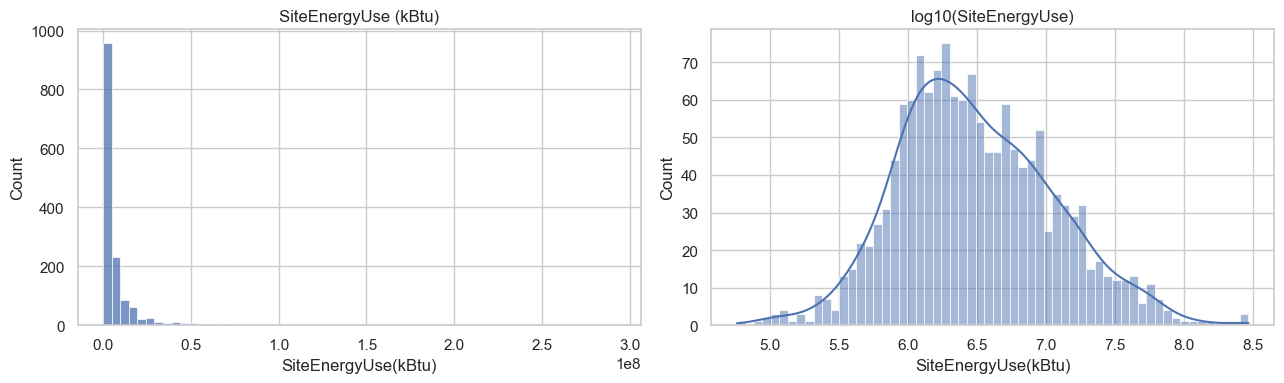

Asymétrie brute : 8.9 — après log : 0.30


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[cible], bins=60, ax=axes[0])
axes[0].set_title("SiteEnergyUse (kBtu)")
sns.histplot(np.log10(df[cible]), bins=60, kde=True, ax=axes[1])
axes[1].set_title("log10(SiteEnergyUse)")
plt.tight_layout()
plt.show()
print(f"Asymétrie brute : {df[cible].skew():.1f} — après log : {np.log10(df[cible]).skew():.2f}")

Un histogramme compte combien de bâtiments tombent dans chaque tranche de consommation.
À gauche, la consommation brute ; à droite, la même chose en échelle log.

- **À gauche**, presque tous les bâtiments sont écrasés contre zéro, avec une longue traîne vers la droite : quelques très gros sites
  (campus, hôpitaux) consomment des centaines de millions de kBtu, la plupart seulement quelques millions.
- **À droite**, en échelle log, on obtient une **cloche** régulière.
- L'asymétrie (0 = parfaitement symétrique) passe de **8,9 à 0,30** grâce au log.

**Conclusion** : on modélisera probablement `log(consommation)`. Sinon, les quelques géants domineraient l'erreur du modèle,
qui prédirait mal tous les autres bâtiments.

In [52]:
df.sort_values(cible, ascending=False)[["PrimaryPropertyType", "NumberofBuildings", "PropertyGFATotal", cible]].head(10)

,PrimaryPropertyType,NumberofBuildings,PropertyGFATotal,SiteEnergyUse(kBtu)
OSEBuildingID,,,,
828,Hospital,7.0,1765970,291614432.0
753,Other,1.0,429405,274682208.0
198,Hospital,6.0,879000,253832464.0
268,Hospital,6.0,597519,143423024.0
477,Other,1.0,535947,131373880.0
22062,University,1.0,2200000,114648520.0
23113,Medical Office,1.0,591981,102673696.0
775,Large Office,1.0,1952220,92937640.0
25251,University,14.0,537000,90609640.0


Les 10 plus gros consommateurs. Ce sont des **hôpitaux**, des **universités** et des bureaux ou hôtels gigantesques
(jusqu'à 2,2 millions de pieds²). Ce ne sont pas des erreurs : ce sont de vrais très grands sites, **on les garde**. Mais ils confirment
pourquoi le passage au log est nécessaire.

#### Consommation selon l'usage

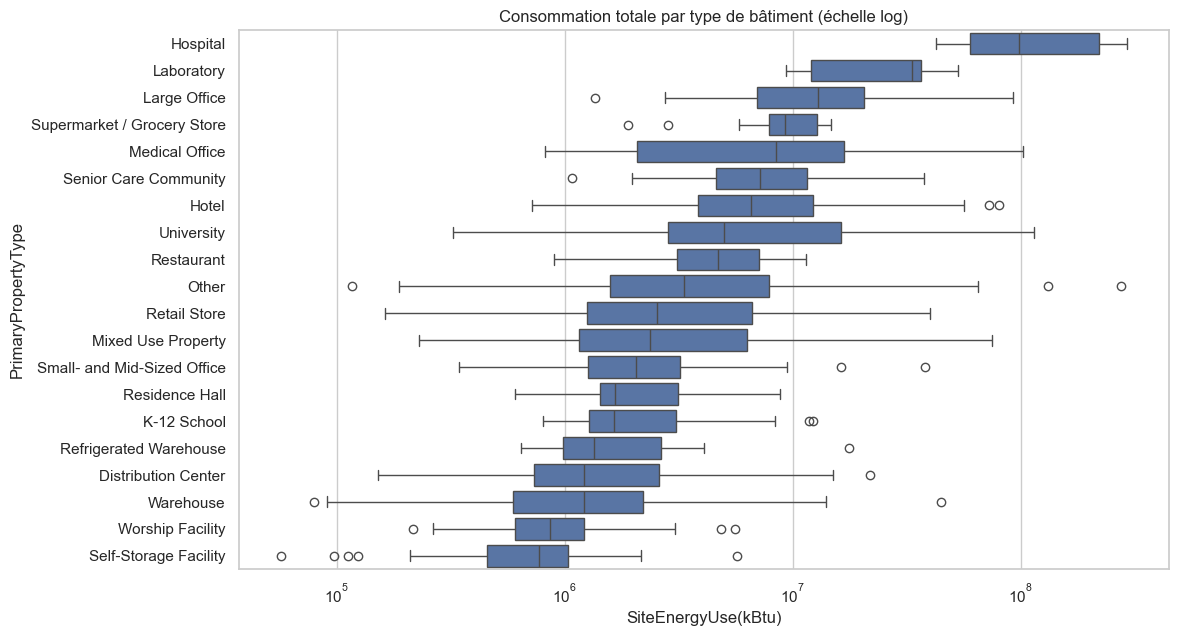

In [53]:
ordre = df.groupby("PrimaryPropertyType")[cible].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=df, y="PrimaryPropertyType", x=cible, order=ordre, log_scale=True, ax=ax)
ax.set_title("Consommation totale par type de bâtiment (échelle log)")
plt.show()

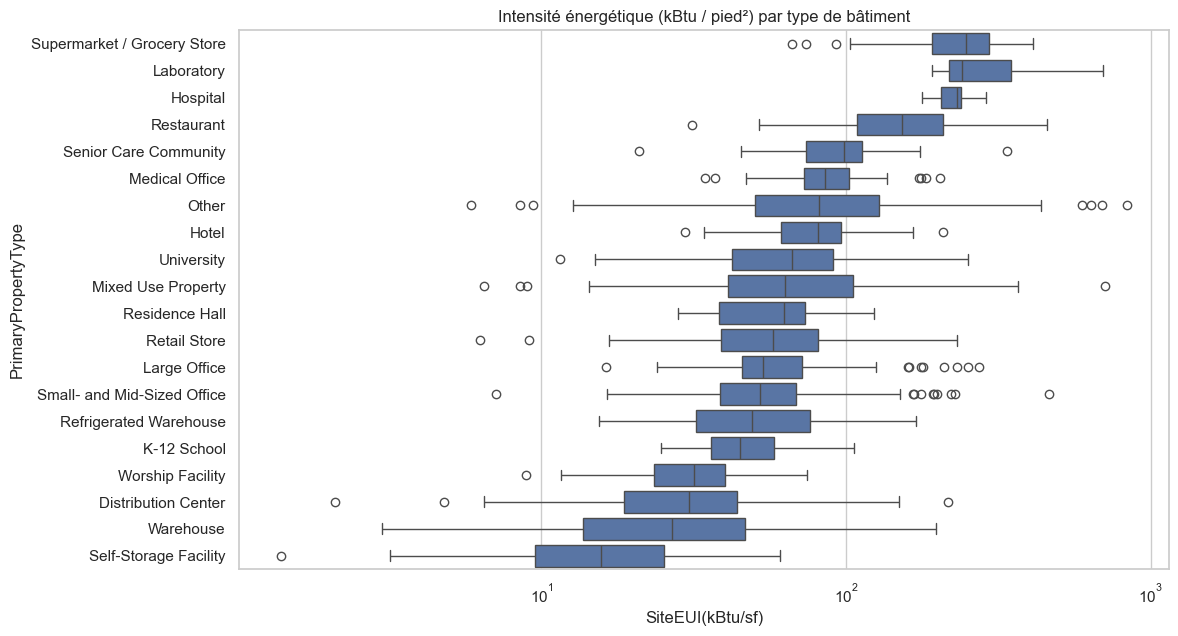

In [54]:
fig, ax = plt.subplots(figsize=(12, 7))
ordre_eui = df.groupby("PrimaryPropertyType")["SiteEUI(kBtu/sf)"].median().sort_values(ascending=False).index
sns.boxplot(data=df, y="PrimaryPropertyType", x="SiteEUI(kBtu/sf)", order=ordre_eui, log_scale=True, ax=ax)
ax.set_title("Intensité énergétique (kBtu / pied²) par type de bâtiment")
plt.show()

Un *boxplot* (boîte à moustaches) par type de bâtiment. Le trait au milieu de la boîte est la **médiane** ;
la boîte contient la moitié centrale des bâtiments ; les points isolés sont des bâtiments hors norme. Les types sont triés du plus au moins consommateur.
Le premier graphique montre la consommation totale, le second la consommation **par pied²** (EUI), qui neutralise l'effet de la taille.

- En consommation totale, les **hôpitaux, laboratoires et grands bureaux** consomment le plus : ce sont aussi les plus grands.
- Ramenée à la surface (EUI), la hiérarchie change : **supermarchés, restaurants, hôpitaux et laboratoires** sont les plus intensifs
  (froid, cuisson, équipements 24 h/24), **entrepôts et self-stockage** les plus sobres.

**Conclusion** : l'**usage** du bâtiment est une information clé, à combiner avec la **surface**.

#### Consommation et surface

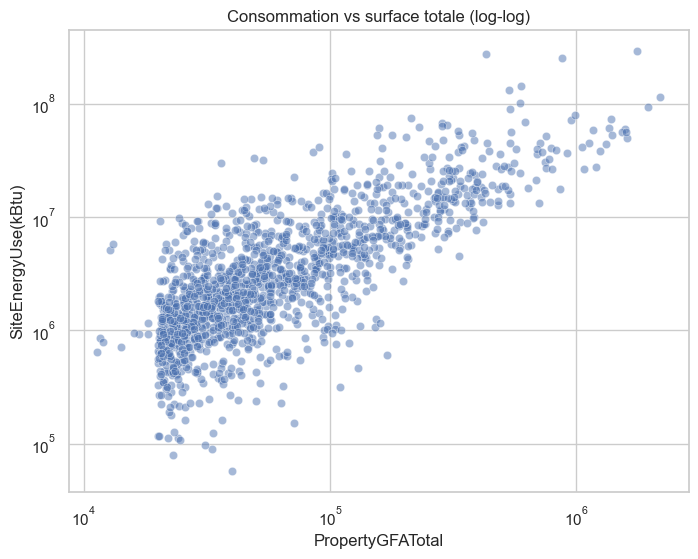

Corrélation log-log : 0.77


In [55]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df, x="PropertyGFATotal", y=cible, alpha=0.5, ax=ax)
ax.set(xscale="log", yscale="log", title="Consommation vs surface totale (log-log)")
plt.show()
print("Corrélation log-log :", round(np.corrcoef(np.log10(df["PropertyGFATotal"]), np.log10(df[cible]))[0, 1], 2))

Chaque point est un bâtiment, placé selon sa surface (horizontal) et sa consommation (vertical),
les deux axes en échelle log.

Les points forment une **bande droite qui monte** : plus un bâtiment est grand, plus il consomme, de façon très régulière.
La corrélation de **0,77** (sur 1) confirme un lien fort. Les écarts verticaux autour de la bande s'expliquent surtout par l'**usage** vu plus haut.

**Conclusion** : la **surface** est le facteur n°1 de la consommation.

#### Âge, hauteur et localisation

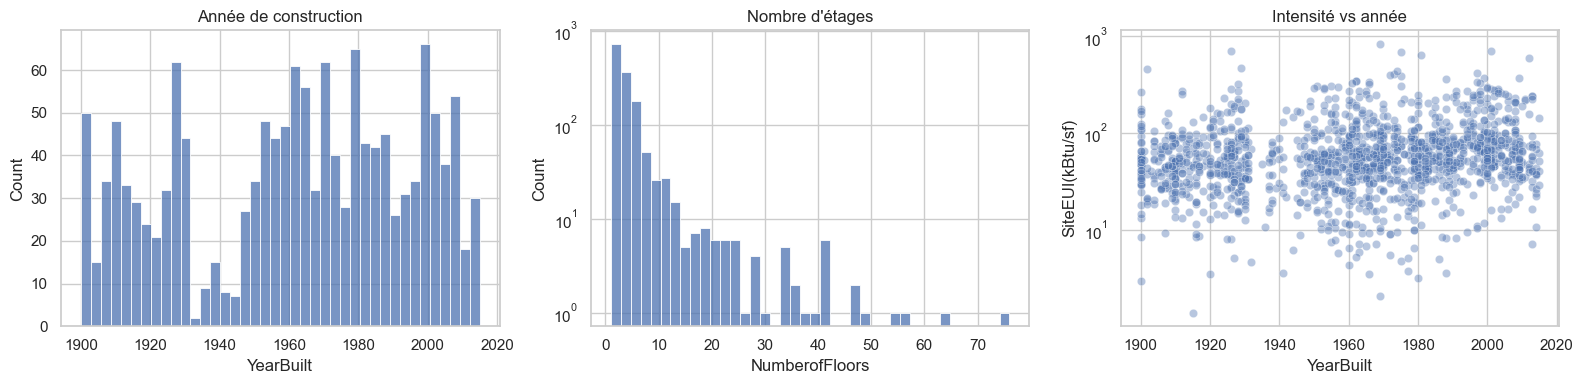

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["YearBuilt"], bins=40, ax=axes[0]).set_title("Année de construction")
sns.histplot(df["NumberofFloors"], bins=40, ax=axes[1]).set_title("Nombre d'étages")
axes[1].set_yscale("log")
sns.scatterplot(data=df, x="YearBuilt", y="SiteEUI(kBtu/sf)", alpha=0.4, ax=axes[2]).set_title("Intensité vs année")
axes[2].set_yscale("log")
plt.tight_layout()
plt.show()

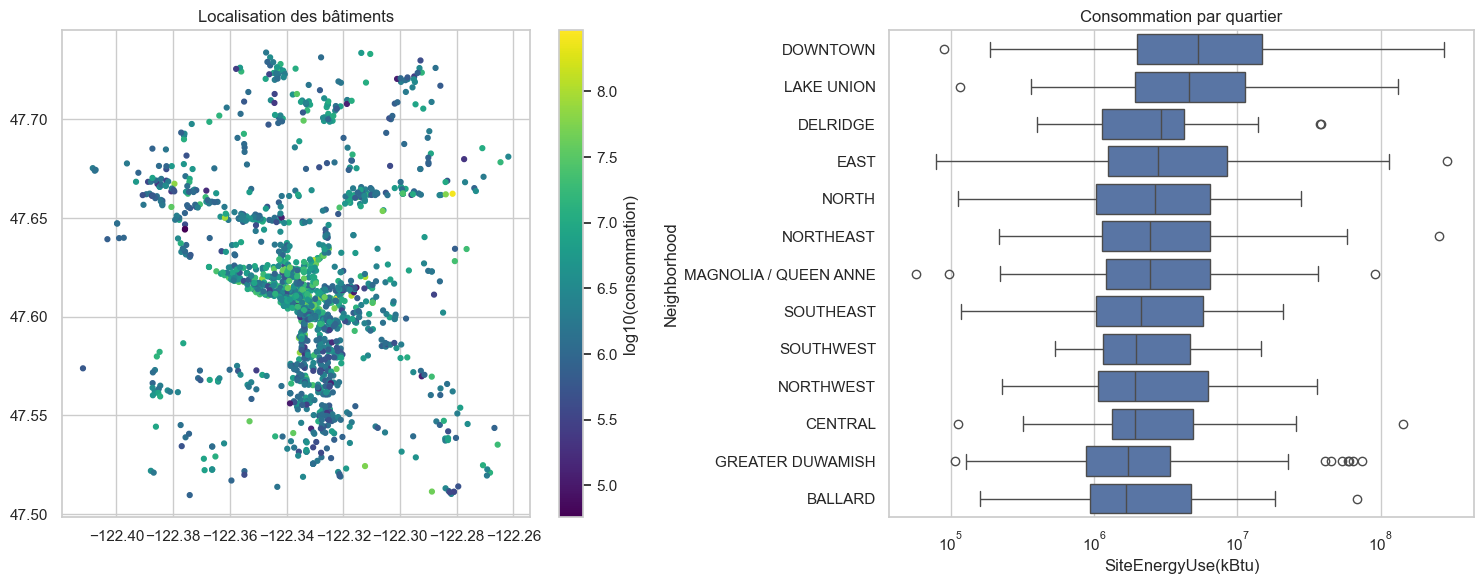

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sc = axes[0].scatter(df["Longitude"], df["Latitude"], c=np.log10(df[cible]), cmap="viridis", s=12)
plt.colorbar(sc, ax=axes[0], label="log10(consommation)")
axes[0].set_title("Localisation des bâtiments")
ordre_q = df.groupby("Neighborhood")[cible].median().sort_values(ascending=False).index
sns.boxplot(data=df, y="Neighborhood", x=cible, order=ordre_q, log_scale=True, ax=axes[1])
axes[1].set_title("Consommation par quartier")
plt.tight_layout()
plt.show()

1ʳᵉ figure — nombre de bâtiments par année de construction, par nombre d'étages (axe vertical en log
pour voir les rares tours), et intensité énergétique selon l'année. 2ᵉ figure — carte de Seattle (chaque point est un bâtiment, couleur claire =
forte consommation) et consommation par quartier.

- Le parc est **ancien** : médiane en 1965, un quart des bâtiments construits avant 1930, pics dans les années 1920 et 1960.
  L'année de construction n'est que **faiblement** liée à l'intensité énergétique (le nuage de points ne montre pas de tendance nette).
- Les trois quarts des bâtiments font moins de 5 étages ; les tours (20 étages et plus) sont presque toutes à **Downtown**.
- Sur la carte, les gros consommateurs se concentrent au **centre** (Downtown, Lake Union) : c'est là que se trouvent les grands bureaux,
  hôtels et hôpitaux.

**Conclusion** : l'âge et le quartier ont un effet **faible ou indirect** — l'« effet quartier » reflète surtout le type et la taille des bâtiments.

#### Sources d'énergie

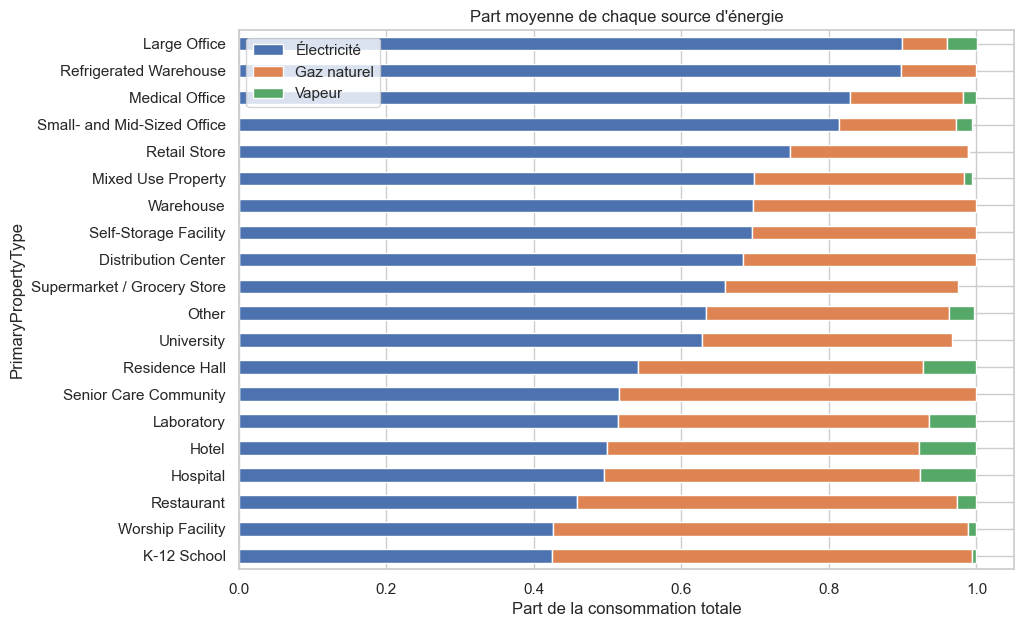

Part moyenne sur l'ensemble : {'Électricité': 0.7, 'Gaz naturel': 0.27, 'Vapeur': 0.02}
Bâtiments utilisant du gaz : 0.71 — de la vapeur : 0.07


In [58]:
sources = {"Électricité": "Electricity(kBtu)", "Gaz naturel": "NaturalGas(kBtu)", "Vapeur": "SteamUse(kBtu)"}
mix = pd.DataFrame({nom: df[col] / df[cible] for nom, col in sources.items()})
mix["PrimaryPropertyType"] = df["PrimaryPropertyType"]
mix_type = mix.groupby("PrimaryPropertyType").mean().sort_values("Électricité")
mix_type.plot(kind="barh", stacked=True, figsize=(10, 7), title="Part moyenne de chaque source d'énergie")
plt.xlabel("Part de la consommation totale")
plt.show()
print("Part moyenne sur l'ensemble :", mix[list(sources)].mean().round(2).to_dict())
print("Bâtiments utilisant du gaz :", (df["NaturalGas(kBtu)"] > 0).mean().round(2),
      "— de la vapeur :", (df["SteamUse(kBtu)"] > 0).mean().round(2))

Une barre par type de bâtiment, découpée selon la part de chaque énergie dans sa consommation
(électricité, gaz, vapeur du réseau urbain). Une barre entièrement d'une couleur = une seule source d'énergie.

- L'**électricité** domine : environ **70 %** de la consommation en moyenne, et quasiment tous les bâtiments l'utilisent.
- Le **gaz** (27 % en moyenne, utilisé par 71 % des bâtiments) dépasse la moitié de la consommation dans les écoles, lieux de culte et
  restaurants (chauffage, cuisson).
- La **vapeur** (réseau de chaleur urbain) ne concerne que **7 %** des bâtiments, surtout à Downtown et dans le quartier East (hôpitaux).

Ces quantités proviennent du relevé : elles éclairent l'analyse mais ne seront **pas** utilisées comme features (fuite de données).

#### Type de bâtiment et quartier (quali vs quali)

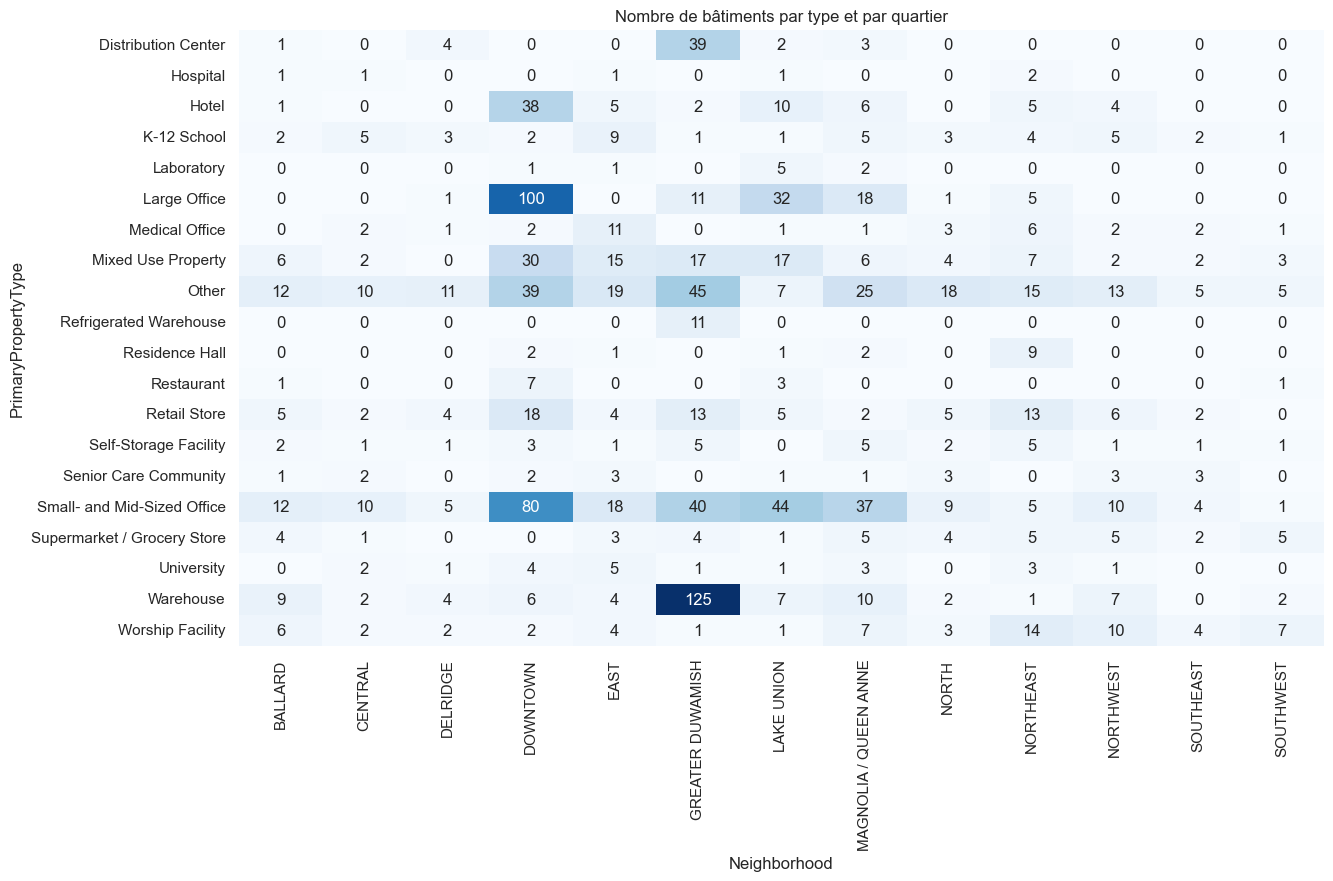

In [59]:
croise = pd.crosstab(df["PrimaryPropertyType"], df["Neighborhood"])
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(croise, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Nombre de bâtiments par type et par quartier")
plt.show()

Un tableau croisé type de bâtiment × quartier. Chaque case donne le **nombre de bâtiments** d'un type dans un quartier ;
plus la case est foncée, plus il y en a.

- Les **grands bureaux** et les **hôtels** sont concentrés à **Downtown** (environ 60 % et 55 %) et à **Lake Union**.
- Les **entrepôts** et **centres de distribution** sont massivement à **Greater Duwamish** (zone industrielle et portuaire) :
  environ 70 % des entrepôts et 80 % des centres de distribution.
- Les **lieux de culte** et **supermarchés** sont répartis dans les quartiers résidentiels (Northeast, Northwest, Magnolia / Queen Anne).

**Conclusion** : le quartier et le type de bâtiment sont liés. L'« effet quartier » sur la consommation est en partie un effet type.

#### Corrélations

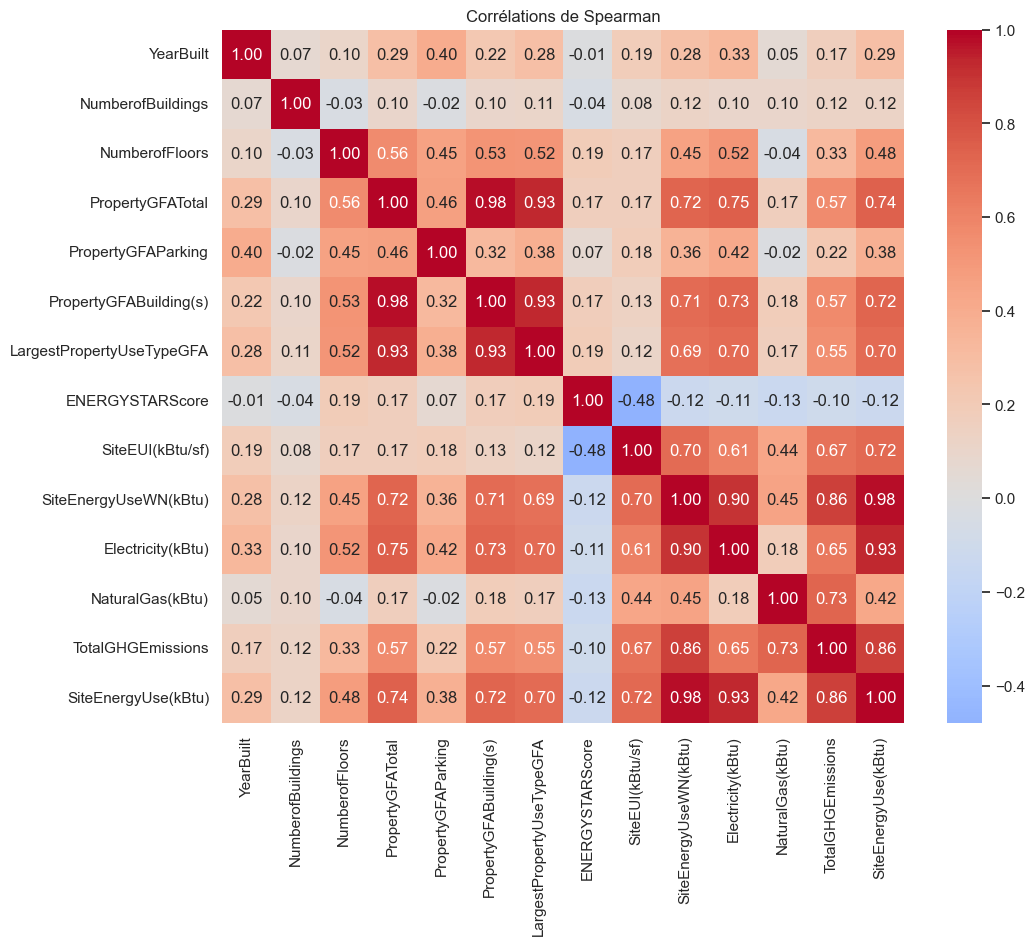

In [60]:
cols_corr = ["YearBuilt", "NumberofBuildings", "NumberofFloors", "PropertyGFATotal", "PropertyGFAParking",
             "PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA", "ENERGYSTARScore",
             "SiteEUI(kBtu/sf)", "SiteEnergyUseWN(kBtu)", "Electricity(kBtu)", "NaturalGas(kBtu)",
             "TotalGHGEmissions", cible]
corr = df[cols_corr].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Corrélations de Spearman")
plt.show()

Chaque case donne la corrélation entre deux colonnes, de -1 à 1. **Rouge foncé** = lien positif fort
(les deux augmentent ensemble), **bleu** = lien négatif, **blanc** = pas de lien. La diagonale vaut toujours 1 (une colonne avec elle-même).
On utilise la corrélation de **Spearman** (basée sur le classement des valeurs), plus fiable que la corrélation classique avec des valeurs aussi déséquilibrées.

- `SiteEnergyUseWN`, `Electricity`, `TotalGHGEmissions` sont très fortement corrélées à la cible (0,86 à 0,98) : ce sont des **mesures de la même chose**
  → fuite de données, à exclure.
- Les surfaces `PropertyGFATotal`, `PropertyGFABuilding(s)`, `LargestPropertyUseTypeGFA` sont **redondantes** entre elles (> 0,9) : elles disent la même chose,
  il faudra n'en garder qu'une partie.
- Parmi les variables utilisables, la **surface** est de loin la plus liée à la consommation (≈ 0,74) ; viennent ensuite le nombre d'étages (≈ 0,48),
  la surface de parking (≈ 0,38) et l'année de construction (≈ 0,29).

### 5. Synthèse de l'analyse exploratoire

1. **Périmètre** : **1 454 bâtiments** non résidentiels (sur 3 376 au départ) avec un relevé conforme, une consommation positive et des
   caractéristiques cohérentes (voir le journal des filtrages). Les écoles publiques sont sous-représentées.
2. **Cible très asymétrique** → modélisation sur `log(consommation)` à envisager, et vigilance sur les très gros sites (campus, hôpitaux).
3. **Surface** = premier facteur de consommation (relation linéaire en log-log).
4. **Usage** = second facteur : à surface égale, un supermarché ou un hôpital consomme bien plus qu'un entrepôt.
5. **Localisation et âge** ont un effet faible ou indirect (Downtown concentre les grands bâtiments).
6. **Fuite de données** : intensités, consommations par source, émissions et ENERGY STAR Score sont issues du relevé → exclues des features.

#### Sélection des colonnes utiles pour la suite

L'analyse est terminée : on ne garde que **12 colonnes** utiles pour construire les features, plus la cible.
Les colonnes retirées ont servi à **analyser** les données, mais n'ont pas leur place dans le modèle.

Les quantités de gaz et de vapeur ne peuvent pas être utilisées (elles composent la cible : fuite de données). En revanche, savoir si le bâtiment
**est équipé** au gaz ou **raccordé** au réseau de vapeur est une information structurelle, connue sans relevé de consommation.
On remplace donc ces deux quantités par deux colonnes oui / non (1 / 0). Pas d'équivalent pour l'électricité : la quasi-totalité des bâtiments l'utilisent,
la colonne vaudrait 1 partout.

**Colonnes conservées**

| Colonne | Justification |
|---|---|
| `PrimaryPropertyType` | Usage principal : 2ᵉ facteur de consommation (un supermarché consomme bien plus qu'un entrepôt de même taille) |
| `ListOfAllPropertyUseTypes` | Liste de tous les usages : repère les usages très énergivores (restaurant, data center…) même secondaires |
| `LargestPropertyUseTypeGFA` | Surface de l'usage principal : indique si le bâtiment est mono-usage ou mixte |
| `Neighborhood` | Quartier : résume la localisation en 13 modalités |
| `YearBuilt` | Année de construction : les normes énergétiques ont évolué au fil des époques |
| `NumberofBuildings` | Nombre de bâtiments : distingue un bâtiment isolé d'un campus |
| `NumberofFloors` | Nombre d'étages : distingue un entrepôt de plain-pied d'une tour |
| `PropertyGFATotal` | Surface totale : 1er facteur de consommation (relation linéaire en log-log) |
| `PropertyGFAParking` | Surface de parking : peu consommatrice comparée aux bureaux ou commerces |
| `PropertyGFABuilding(s)` | Surface bâtie hors parking : sert à calculer la surface par étage |
| `UtiliseGaz` | 1 si le bâtiment est équipé au gaz (chauffage, cuisson) : équipement connu sans relevé |
| `UtiliseVapeur` | 1 si le bâtiment est raccordé au réseau de vapeur urbain : équipement connu sans relevé |
| `SiteEnergyUse(kBtu)` | **Cible** à prédire |

**Colonnes retirées**

| Colonne | Justification |
|---|---|
| `OSEBuildingID` | Identifiant : un numéro attribué par la ville, sans lien avec la consommation |
| `ENERGYSTARScore`, `SiteEUI`, `SiteEUIWN`, `SourceEUI`, `SourceEUIWN`, `SiteEnergyUseWN` | Calculées à partir des consommations relevées → **fuite de données** |
| `Electricity(kWh)`, `Electricity(kBtu)`, `NaturalGas(therms)`, `NaturalGas(kBtu)`, `SteamUse(kBtu)` | Quantités consommées, issues du relevé → **fuite de données** (gaz et vapeur remplacés par `UtiliseGaz` / `UtiliseVapeur`) |
| `TotalGHGEmissions`, `GHGEmissionsIntensity` | Émissions calculées à partir des consommations → **fuite de données** |
| `ZipCode`, `CouncilDistrictCode`, `Latitude`, `Longitude` | Localisation déjà donnée par `Neighborhood` ; l'analyse a montré que l'effet du lieu est faible et passe surtout par le type de bâtiment |
| `BuildingType` | A servi au filtrage ; redondante avec `PrimaryPropertyType` |
| `LargestPropertyUseType` | Quasi identique à `PrimaryPropertyType` |
| `SecondLargestPropertyUseType`, `ThirdLargestPropertyUseType` | Noms des usages secondaires, déjà présents dans `ListOfAllPropertyUseTypes` |
| `SecondLargestPropertyUseTypeGFA`, `ThirdLargestPropertyUseTypeGFA` | Surfaces des usages secondaires, souvent absentes ou petites : apport faible, et la surface de l'usage principal indique déjà si le bâtiment est mixte |

In [61]:
# Présence d'une source d'énergie (oui / non), jamais la quantité consommée
df["UtiliseGaz"] = (df["NaturalGas(kBtu)"] > 0).astype(int)
df["UtiliseVapeur"] = (df["SteamUse(kBtu)"] > 0).astype(int)

colonnes_conservees = [
    # Usage
    "PrimaryPropertyType", "ListOfAllPropertyUseTypes", "LargestPropertyUseTypeGFA",
    # Localisation
    "Neighborhood",
    # Bâti
    "YearBuilt", "NumberofBuildings", "NumberofFloors",
    "PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
    # Équipements
    "UtiliseGaz", "UtiliseVapeur",
    # Cible
    cible,
]
df_export = df[colonnes_conservees].reset_index(drop=True)
print(f"Colonnes conservées : {df_export.shape[1]} (12 informations + la cible)")
df_export.columns.tolist()

Colonnes conservées : 13 (12 informations + la cible)


['PrimaryPropertyType',
 'ListOfAllPropertyUseTypes',
 'LargestPropertyUseTypeGFA',
 'Neighborhood',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'PropertyGFAParking',
 'PropertyGFABuilding(s)',
 'UtiliseGaz',
 'UtiliseVapeur',
 'SiteEnergyUse(kBtu)']

#### Export du jeu nettoyé

La suite (feature engineering et modélisation) est dans `02_modelisation.ipynb`, pour alléger ce notebook.

In [62]:
df_export.to_csv("../data/building_consumption_clean.csv", index=False)
print(f"Export : {df_export.shape[0]} bâtiments, {df_export.shape[1]} colonnes")

Export : 1454 bâtiments, 13 colonnes


Le jeu nettoyé (**1 454 bâtiments, 11 colonnes**) est enregistré dans `data/building_consumption_clean.csv`.
C'est le point de départ du notebook `02_modelisation.ipynb`.